<img src="assets/udc1.png" alt="UDC"/>

# Notebook pour la classification d'images(déchets) avec JEPA. 

In [ ]:
# Initialisation : rend le paquet `src` importable quel que soit le dossier de lancement
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src
from src.utils.paths import (
    CLS_MODELS_DIR,
    DATASET_ANOMALIES,
    DATASET_PUBLIC,
    DATASET_VALIDATION,
    FIGURES_DIR,
)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os 
import pandas as pd
import math
import random

In [ ]:
import tensorflow as tf
tf.config.run_functions_eagerly(True)

In [3]:
df = src.Load_data.load_object(DATASET_PUBLIC)

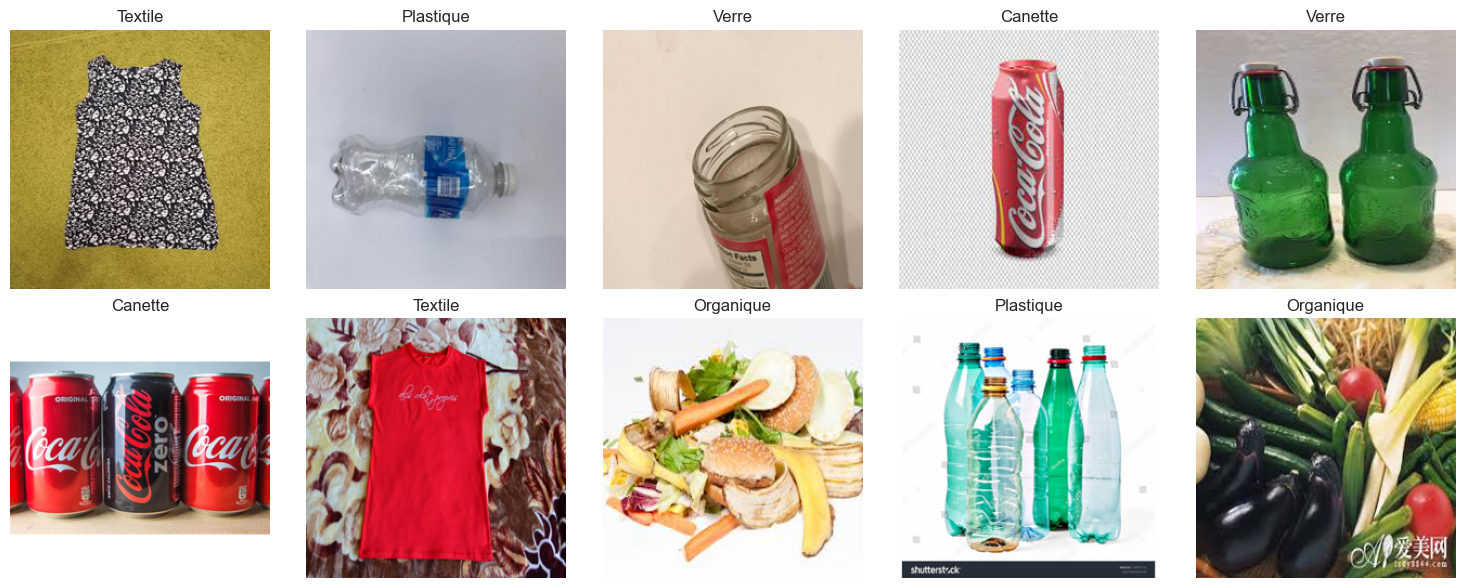

In [4]:
df.plot(n_samples=10)

In [5]:
df.reshape(target_shape=(64, 64, 3))

Reshape en batch:   0%|          | 0/380 [00:00<?, ?it/s]

Reshape en batch: 100%|██████████| 380/380 [00:22<00:00, 16.99it/s]


In [6]:
df.encodage()

Encodage effectué. Mapping: {'Canette': 0, 'Organique': 1, 'Plastique': 2, 'Textile': 3, 'Verre': 4}


In [7]:
(X_train, y_train), (X_test, y_test) = df.create_data(test_size=0.2)

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [9]:
from tensorflow import keras
from keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import Adam,SGD,RMSprop
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from tensorflow.keras.callbacks import LearningRateScheduler,ModelCheckpoint,ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
import tensorflow as tf
from tensorflow.keras import layers, regularizers, Model, Input
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.layers import Dense, Dropout, Add, BatchNormalization, Input, Flatten
from keras.saving import register_keras_serializable

In [10]:
# Dimensions
IMG_HEIGHT = 64
IMG_WIDTH = 64
IMG_CHANNELS = 3
EMBED_DIM = 128           # Dimension de l'espace latent
NUM_CLASSES = 5
BATCH_SIZE = 64
EPOCHS_JEPA = 100          # Pré-entraînement auto-supervisé
EPOCHS_CLASS = 50         # Classification supervisée
EMA_DECAY = 0.99          # Pour l'encodeur cible
PATCH_SIZE = 8

In [11]:
@register_keras_serializable()
class PatchExtractor(layers.Layer):
    """Extrait des patches et les reshape pour le transformer."""
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        # images: (batch, H, W, C)
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding='VALID'
        )
        batch_size = tf.shape(images)[0]
        num_patches = (tf.shape(images)[1] // self.patch_size) ** 2
        patch_dim = patches.shape[-1]  # channels * patch_size * patch_size
        patches = tf.reshape(patches, (batch_size, num_patches, patch_dim))
        return patches



In [12]:
@register_keras_serializable()
def build_encoder(embed_dim=128, input_shape=(64, 64, 3), patch_size=8):
    """Encodeur simple compatible avec IJEPADataGenerator."""
    num_patches = (input_shape[0] // patch_size) ** 2
    inputs = layers.Input(shape=input_shape)

    # CNN
    x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)

    # Extraire les patches via notre couche
    patches = PatchExtractor(patch_size)(x)

    # Dense pour embed_dim
    embeddings = layers.Dense(embed_dim, activation='relu')(patches)

    return Model(inputs, embeddings, name='encoder')

In [13]:
EMBED_DIM = 128  
NUM_CLASSES = 5  


@register_keras_serializable()
def build_predictor(embed_dim=EMBED_DIM, hidden_dim=256):
    """
    Predictor simple mais puissant pour IJEPA.
    - Prend en entrée les embeddings de patchs (batch, num_patches, embed_dim)
    - Retourne les embeddings prédits pour les patches masqués
    """
    inputs = tf.keras.Input(shape=(None, embed_dim), name='predictor_input')
    
    # Bloc Transformer-like simple pour prédiction
    x = layers.LayerNormalization()(inputs)
    x = layers.Dense(hidden_dim, activation='relu')(x)
    x = layers.Dense(embed_dim)(x)  # sortie embed_dim par patch
    
    return Model(inputs, x, name='predictor')


In [14]:
@register_keras_serializable()
def build_classifier(embed_dim=EMBED_DIM, num_classes=NUM_CLASSES,
                     hidden_dims=[128, 64], dropout_rate=0.2):
   
    inputs = tf.keras.Input(shape=(embed_dim,), name='classifier_input')
    x = inputs
    
    for i, hidden_dim in enumerate(hidden_dims):
        x = layers.Dense(hidden_dim, kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Dropout(dropout_rate)(x)
    
    outputs = layers.Dense(num_classes, name='logits')(x)
    
    return Model(inputs, outputs, name='classifier')

In [15]:
class JEPAMaskingConfig:
    """
    Configuration du masquage selon l'article I-JEPA.
    
    Référence: Section 3 - Method, et Appendix C
    """
    
    def __init__(self, img_size=224, patch_size=16):
        """
        Args:
            img_size: taille de l'image en pixels (H=W)
            patch_size: taille de chaque patch en pixels
        """
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.grid_size = img_size // patch_size
        
        # Paramètres des cibles (target blocks) - Section 3
        self.target_scale_min = 0.15      # Échelle min des blocs cibles
        self.target_scale_max = 0.20      # Échelle max des blocs cibles
        self.target_aspect_min = 0.75     # Ratio d'aspect min
        self.target_aspect_max = 1.5      # Ratio d'aspect max
        self.num_targets = 4              # Nombre de blocs cibles (M=4)
        
        # Paramètres du contexte (context block) - Section 3
        self.context_scale_min = 0.85     # Échelle min du bloc contexte
        self.context_scale_max = 1.0      # Échelle max du bloc contexte
        self.context_aspect = 1.0         # Ratio d'aspect du contexte (carré)


In [16]:

class JEPAMaskGenerator:
    """
    Générateur de masques pour I-JEPA.
    Produit les indices des patches pour le contexte et les cibles.
    
    Référence: Section 3 - Method, "Masking strategy"
    """
    
    def __init__(self, config):
        self.config = config
        
    def _random_block(self, scale_min, scale_max, aspect_min=None, aspect_max=None, aspect_fixed=None):
       
        grid = self.config.grid_size
        
        # Échelle en nombre de patches
        scale = random.uniform(scale_min, scale_max)
        area = scale * scale * grid * grid  # surface en nombre de patches
        
        # Ratio d'aspect
        if aspect_fixed is not None:
            aspect = aspect_fixed
        else:
            aspect = random.uniform(aspect_min, aspect_max)
        
        # Dimensions en patches
        w_patches = int(round(math.sqrt(area * aspect)))
        h_patches = int(round(math.sqrt(area / aspect)))
        
        # Ajuster pour rester dans les limites
        w_patches = min(w_patches, grid - 1)
        h_patches = min(h_patches, grid - 1)
        
        if w_patches < 1:
            w_patches = 1
        if h_patches < 1:
            h_patches = 1
        
        # Position aléatoire
        x = random.randint(0, grid - w_patches)
        y = random.randint(0, grid - h_patches)
        
        return x, y, w_patches, h_patches
    
    def _block_to_indices(self, x, y, w, h):
        
        grid = self.config.grid_size
        indices = []
        for row in range(y, y + h):
            for col in range(x, x + w):
                idx = row * grid + col
                indices.append(idx)
        return indices
    
    def generate_masks(self, batch_size):
        
        context_masks = []
        target_masks_list = []
        
        for _ in range(batch_size):
            # 1. Générer les blocs cibles (M=4)
            target_blocks = []
            target_blocks_coords = []
            
            for _ in range(self.config.num_targets):
                x, y, w, h = self._random_block(
                    self.config.target_scale_min,
                    self.config.target_scale_max,
                    self.config.target_aspect_min,
                    self.config.target_aspect_max
                )
                target_blocks.append(self._block_to_indices(x, y, w, h))
                target_blocks_coords.append((x, y, w, h))
            
            # 2. Générer le bloc contexte
            ctx_x, ctx_y, ctx_w, ctx_h = self._random_block(
                self.config.context_scale_min,
                self.config.context_scale_max,
                aspect_fixed=self.config.context_aspect
            )
            context_idx = set(self._block_to_indices(ctx_x, ctx_y, ctx_w, ctx_h))
            
            # 3. Supprimer les chevauchements avec les cibles
            #    (comme décrit dans l'article: "remove any overlapping regions from the context block")
            for target_block in target_blocks:
                context_idx = context_idx - set(target_block)
            
            # Sauvegarder
            context_masks.append(list(context_idx))
            target_masks_list.append(target_blocks)
        
        return context_masks, target_masks_list
    
    def visualize_masks(self, image, context_mask, target_masks):
       
        grid = self.config.grid_size
        patch_size = self.config.patch_size
        h, w = image.shape[:2]
        
        # Créer une copie
        vis = image.copy().astype(np.uint8)
        
        # Couleurs pour les cibles (RGB)
        colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0)]
        
        # Dessiner les cibles
        for i, target_mask in enumerate(target_masks):
            color = colors[i % len(colors)]
            for idx in target_mask:
                row = idx // grid
                col = idx % grid
                y1 = row * patch_size
                x1 = col * patch_size
                y2 = y1 + patch_size
                x2 = x1 + patch_size
                # Mélanger l'image originale avec la couleur
                vis[y1:y2, x1:x2] = vis[y1:y2, x1:x2] * 0.4 + np.array(color) * 0.6
        
        # Dessiner le contexte (en cyan)
        for idx in context_mask:
            row = idx // grid
            col = idx % grid
            y1 = row * patch_size
            x1 = col * patch_size
            y2 = y1 + patch_size
            x2 = x1 + patch_size
            vis[y1:y2, x1:x2] = vis[y1:y2, x1:x2] * 0.4 + np.array([0, 255, 255]) * 0.6
        
        return vis


In [17]:
class IJEPADataGenerator(tf.keras.utils.Sequence):
    """
    Générateur de données pour I-JEPA avec masquage.
    Retourne ((images_masquees, target_data), labels)
    """
    
    def __init__(self, images, labels=None, batch_size=32, img_size=64, patch_size=8, shuffle=True):
        self.images = images.astype(np.float32)
        self.labels = labels
        self.batch_size = batch_size
        self.img_size = img_size
        self.patch_size = patch_size
        self.shuffle = shuffle
        
        self.config = JEPAMaskingConfig(img_size, patch_size)
        self.mask_generator = JEPAMaskGenerator(self.config)
        
        self.indices = np.arange(len(images))
        if shuffle:
            np.random.shuffle(self.indices)
    
    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))
    
    def _apply_mask_to_image(self, image, context_mask):
        grid = self.config.grid_size
        patch_size = self.config.patch_size
        masked_image = np.zeros_like(image, dtype=np.float32)
        
        for idx in context_mask:
            row = idx // grid
            col = idx % grid
            y1 = row * patch_size
            x1 = col * patch_size
            y2 = y1 + patch_size
            x2 = x1 + patch_size
            masked_image[y1:y2, x1:x2] = image[y1:y2, x1:x2]
        
        return masked_image
    
    def _pad_target_masks(self, target_masks_list):
        """
        Pad les target_masks pour qu'ils aient tous la même taille.
        """
        batch_size = len(target_masks_list)
        if batch_size == 0:
            return np.array([]), np.array([])
        
        num_targets = len(target_masks_list[0])
        
        #  Calcul correct de max_patches
        max_patches = 0
        for masks in target_masks_list:
            for m in masks:
                max_patches = max(max_patches, len(m))
        
        #  Si max_patches est trop petit, au moins 4
        max_patches = max(max_patches, 4)
        
        padded_masks = np.zeros((batch_size, num_targets, max_patches), dtype=np.int32)
        mask_lengths = np.zeros((batch_size, num_targets), dtype=np.int32)
        
        for i, masks in enumerate(target_masks_list):
            for j, m in enumerate(masks):
                length = len(m)
                mask_lengths[i, j] = length
                if length > 0:
                    padded_masks[i, j, :length] = m
        
        return padded_masks, mask_lengths
    
    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_images = self.images[batch_indices]
        batch_images = batch_images / 255.0
        
        # Générer les masques
        context_masks, target_masks_list = self.mask_generator.generate_masks(len(batch_images))
        
        # Appliquer les masques
        context_images = []
        for i, img in enumerate(batch_images):
            masked = self._apply_mask_to_image(img, context_masks[i])
            context_images.append(masked)
        context_images = np.array(context_images, dtype=np.float32)
        
        # Pad les target_masks
        padded_target_masks, mask_lengths = self._pad_target_masks(target_masks_list)
        
        # Convertir en tenseurs
        padded_target_masks = tf.constant(padded_target_masks, dtype=tf.int32)
        mask_lengths = tf.constant(mask_lengths, dtype=tf.int32)
        target_data = (padded_target_masks, mask_lengths)
        
        if self.labels is not None:
            batch_labels = self.labels[batch_indices]
            batch_labels = tf.constant(batch_labels, dtype=tf.int32)
            return (context_images, target_data), batch_labels
        else:
            dummy_labels = tf.zeros(len(batch_indices), dtype=tf.int32)
            return (context_images, target_data), dummy_labels
    
    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)
    
    def visualize_batch(self, batch_idx=0, save_path=None):
        
        
        # Récupérer le batch
        (context_images, target_data), labels = self[batch_idx]
        padded_target_masks, mask_lengths = target_data
        
        # Récupérer les images originales
        batch_indices = self.indices[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        original_images = self.images[batch_indices].astype(np.uint8)
        
        #  Vérifier le type et convertir si nécessaire
        if hasattr(context_images, 'numpy'):
            context_images = context_images.numpy()
        if hasattr(padded_target_masks, 'numpy'):
            padded_target_masks = padded_target_masks.numpy()
        if hasattr(mask_lengths, 'numpy'):
            mask_lengths = mask_lengths.numpy()
        
        # Reconstruire les target_masks
        target_masks_list = []
        for i in range(padded_target_masks.shape[0]):
            masks = []
            for j in range(padded_target_masks.shape[1]):
                length = mask_lengths[i, j] if mask_lengths.ndim > 1 else mask_lengths[j]
                if length > 0:
                    masks.append(padded_target_masks[i, j, :length].tolist())
                else:
                    masks.append([])
            target_masks_list.append(masks)
        
        # Générer les masques de contexte pour la visualisation
        context_masks, _ = self.mask_generator.generate_masks(len(original_images))
        
        n_images = min(4, len(context_images))
        fig, axes = plt.subplots(n_images, 4, figsize=(10, 2 * n_images))
        
        if n_images == 1:
            axes = axes.reshape(1, -1)
        
        for i in range(n_images):
            # 1. Image originale
            axes[i, 0].imshow(original_images[i])
            axes[i, 0].set_title(f"Originale {i+1}")
            axes[i, 0].axis('off')
            
            # 2. Image masquée (seul le contexte)
            axes[i, 1].imshow(context_images[i])
            axes[i, 1].set_title(f"Contexte masqué")
            axes[i, 1].axis('off')
            
            # 3. Visualisation des cibles
            vis_targets = self.mask_generator.visualize_masks(
                original_images[i],
                [],  # pas de contexte pour cette visualisation
                target_masks_list[i]
            )
            axes[i, 2].imshow(vis_targets)
            axes[i, 2].set_title(f"Cibles (4 blocs)")
            axes[i, 2].axis('off')
            
            # 4. Visualisation complète (contexte + cibles)
            vis_full = self.mask_generator.visualize_masks(
                original_images[i],
                context_masks[i],
                target_masks_list[i]
            )
            axes[i, 3].imshow(vis_full)
            axes[i, 3].set_title(f"Contexte + Cibles")
            axes[i, 3].axis('off')
        
        plt.tight_layout()
            
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"Figure sauvegardée: {save_path}")
        
        plt.show()
        plt.close(fig)

In [18]:
X_train.max()

np.float32(255.0)

In [19]:
train_generator = IJEPADataGenerator(
    X_train, y_train,
    batch_size=16,
    img_size=64,
    patch_size=8,
    shuffle=True
)
test_datagen =  ImageDataGenerator(rescale= 1. / 255)

In [20]:
test_generator  = test_datagen.flow(X_test,y_test,batch_size=16)

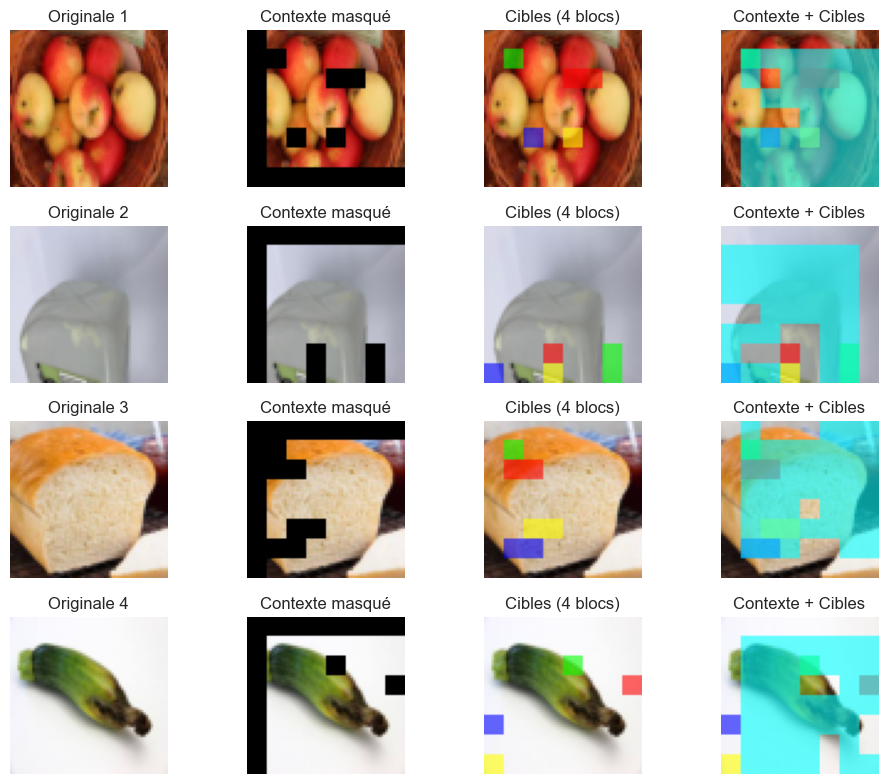

In [21]:
train_generator.visualize_batch(batch_idx=3)

In [22]:
EMBED_DIM = 128
NUM_CLASSES = 5
EMA_DECAY = 0.996
IMG_SIZE = 64
PATCH_SIZE = 8

In [23]:
@register_keras_serializable()
class IJEPAModel(Model):
    """
    Modèle I-JEPA complet.
    """
    
    def __init__(self,
                 embed_dim=EMBED_DIM,
                 num_classes=NUM_CLASSES,
                 num_patches=(IMG_SIZE // PATCH_SIZE) ** 2,
                 lambda_jepa=0.5,
                 ema_decay=EMA_DECAY,
                
                 **kwargs):
        super().__init__(**kwargs)
        
        self.embed_dim = embed_dim
        self.num_classes = num_classes
        self.num_patches = num_patches
        self.lambda_jepa = lambda_jepa
        self.ema_decay = ema_decay
       
        self.encoder = build_encoder(embed_dim)
        self.target_encoder = build_encoder(embed_dim)
        
        self.predictor = build_predictor(embed_dim)
        self.classifier = build_classifier(embed_dim, num_classes)
        
        # Embeddings de position
        self.pos_embedding = self.add_weight(
            name="pos_embedding",
            shape=(1, num_patches, embed_dim),
            initializer="random_normal",
            trainable=True
        )
        
        # Token de masque
        self.mask_token = self.add_weight(
            name="mask_token",
            shape=(1, 1, embed_dim),
            initializer="random_normal",
            trainable=True
        )
        
        # Initialiser l'encodeur cible
        self._init_target_encoder()
        
        # Métriques
        self.loss_tracker = tf.keras.metrics.Mean(name="total_loss")
        self.cls_loss_tracker = tf.keras.metrics.Mean(name="cls_loss")
        self.jepa_loss_tracker = tf.keras.metrics.Mean(name="jepa_loss")
        self.accuracy_tracker = tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    
    def _init_target_encoder(self):
        """Initialise l'encodeur cible avec les poids de l'encodeur source"""
        for w, tw in zip(self.encoder.weights, self.target_encoder.weights):
            tw.assign(w)
        self.target_encoder.trainable = False
    
    def _update_target_encoder(self):
        """Met à jour l'encodeur cible par EMA"""
        for w, tw in zip(self.encoder.weights, self.target_encoder.weights):
            tw.assign(self.ema_decay * tw + (1 - self.ema_decay) * w)
    
    def _get_patch_embeddings(self, encoder, images, training=False):
        """Extrait les embeddings par patch - l'encodeur sort déjà (batch, num_patches, embed_dim)"""
        return encoder(images, training=training)
    
    def compute_jepa_loss(self, images, target_data):
        """
        Calcule la perte JEPA pour les patches cibles.
        target_data = (padded_masks, mask_lengths)
        """
        padded_masks, mask_lengths = target_data

        # Embeddings contexte
        z_context = self._get_patch_embeddings(self.encoder, images, training=True)

        # Embeddings cibles (via target_encoder)
        z_target = self._get_patch_embeddings(self.target_encoder, images, training=False)

        batch_size = tf.shape(z_context)[0]
        num_targets = tf.shape(padded_masks)[1]

        total_loss = tf.constant(0.0, dtype=tf.float32)
        n_valid = tf.constant(0, dtype=tf.float32)

        for b in tf.range(batch_size):
            ctx = z_context[b]        # (num_patches, embed_dim)
            tgt = z_target[b]         # (num_patches, embed_dim)
            masks = padded_masks[b]   # (num_targets, max_patches)
            lengths = mask_lengths[b] # (num_targets,)

            for j in tf.range(num_targets):
                length = lengths[j]

                def valid_case():
                    idx = masks[j, :length]                  # indices valides
                    target_emb = tf.gather(tgt, idx)         # (length, embed_dim)
                    pos = tf.gather(self.pos_embedding[0], idx)  # (length, embed_dim)

                    # Correction: mask_tokens avec les bonnes dimensions
                    # self.mask_token a shape (1, 1, embed_dim) -> on veut (length, embed_dim)
                    mask_tokens = tf.tile(self.mask_token, [length, 1, 1])  # (length, 1, embed_dim)
                    mask_tokens = tf.squeeze(mask_tokens, axis=1)            # (length, embed_dim)
                    mask_tokens = mask_tokens + pos                          # (length, embed_dim)

                    ctx_mean = tf.reduce_mean(ctx, axis=0, keepdims=True)    # (1, embed_dim)
                    ctx_mean = tf.tile(ctx_mean, [length, 1])                # (length, embed_dim)

                    # Entrée du prédicteur: (1, length, embed_dim)
                    pred_input = tf.expand_dims(ctx_mean + mask_tokens, axis=0)

                    # Prédiction
                    pred = self.predictor(pred_input, training=True)  # (1, length, embed_dim)
                    pred = tf.squeeze(pred, axis=0)                   # (length, embed_dim)
                    
                    return tf.reduce_mean(tf.square(pred - target_emb))

                def zero_case():
                    return tf.constant(0.0, dtype=tf.float32)

                loss = tf.cond(length > 0, valid_case, zero_case)
                total_loss += loss
                n_valid += tf.cast(length > 0, tf.float32)

        return total_loss / tf.maximum(n_valid, 1.0)
    
    def call(self, inputs, training=False):
        """
        Forward pass.
        inputs = (images, target_data)
        """
        images, target_data = inputs
        
        # Encodage du contexte
        z_context = self._get_patch_embeddings(self.encoder, images, training=training)
        
        # Classification (moyenne des embeddings contexte)
        z_global = tf.reduce_mean(z_context, axis=1)
        logits = self.classifier(z_global, training=training)
        
        # Perte JEPA
        jepa_loss = None
        if training and target_data is not None:
            # Vérifier que target_data est utilisable
            if isinstance(target_data, (tuple, list)) and len(target_data) == 2:
                if target_data[0] is not None:
                    jepa_loss = self.compute_jepa_loss(images, target_data)
        
        return logits, jepa_loss
    
    def train_step(self, data):
        """Étape d'entraînement"""
        (images, target_data), labels = data
        
        with tf.GradientTape() as tape:
            logits, jepa_loss = self((images, target_data), training=True)
            
            # Perte de classification
            cls_loss = tf.reduce_mean(
                tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
            )
            
            # Perte totale
            if jepa_loss is not None:
                total_loss = cls_loss + self.lambda_jepa * jepa_loss
            else:
                total_loss = cls_loss
        
        # Rétropropagation
        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        
        # Mettre à jour l'encodeur cible (EMA)
        self._update_target_encoder()
        
        # Métriques
        self.loss_tracker.update_state(total_loss)
        self.cls_loss_tracker.update_state(cls_loss)
        if jepa_loss is not None:
            self.jepa_loss_tracker.update_state(jepa_loss)
        self.accuracy_tracker.update_state(labels, logits)
        
        return {
            "total_loss": self.loss_tracker.result(),
            "cls_loss": self.cls_loss_tracker.result(),
            "jepa_loss": self.jepa_loss_tracker.result(),
            "accuracy": self.accuracy_tracker.result()
        }
    
    def test_step(self, data):
    
        """Étape de validation - accepte à la fois les données avec et sans masques"""
        
        #  Gérer les différents formats
        if isinstance(data, (list, tuple)):
            if len(data) == 2:
                # Cas 1: (images, labels) - validation standard
                # Cas 2: ((images, target_data), labels) - avec masques
                if isinstance(data[0], tuple) and len(data[0]) == 2:
                    # Format avec masques: ((images, target_data), labels)
                    (images, target_data), labels = data
                else:
                    # Format sans masques: (images, labels)
                    images, labels = data
                    target_data = None
            elif len(data) == 3:
                # Format: (images, target_data, labels)
                images, target_data, labels = data
            else:
                images = data[0]
                target_data = None
                labels = data[1] if len(data) > 1 else None
        else:
            images = data
            target_data = None
            labels = None
        
        # Forward pass (target_data=None pour les données sans masques)
        logits, jepa_loss = self((images, target_data), training=False)
        
        cls_loss = tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
        )
        
        total_loss = cls_loss
        if jepa_loss is not None:
            total_loss = cls_loss + self.lambda_jepa * jepa_loss
            self.jepa_loss_tracker.update_state(jepa_loss)
        
        self.loss_tracker.update_state(total_loss)
        self.cls_loss_tracker.update_state(cls_loss)
        self.accuracy_tracker.update_state(labels, logits)
        
        return {
            "total_loss": self.loss_tracker.result(),
            "cls_loss": self.cls_loss_tracker.result(),
            "jepa_loss": self.jepa_loss_tracker.result(),
            "accuracy": self.accuracy_tracker.result()
        }
    
    @property
    def metrics(self):
        return [self.loss_tracker, self.cls_loss_tracker, self.jepa_loss_tracker, self.accuracy_tracker]
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_classes": self.num_classes,
            "num_patches": self.num_patches,
            "lambda_jepa": self.lambda_jepa,
            "ema_decay": self.ema_decay,
           
        })
        return config
    
    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [24]:
model = IJEPAModel()

In [31]:
model.encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_extractor_2               │ (None, 64, 8192)       │             0 │
│ (PatchExtractor)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64, 128)        │     1,048,704 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,848 (4.36 MB)

 Trainable params: 1,142,400 (4.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [52]:
model.predictor.summary()


Model: "predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ predictor_input (InputLayer)    │ (None, None, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, None, 128)      │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, None, 256)      │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, None, 128)      │        32,896 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,176 (258.50 KB)

 Trainable params: 66,176 (258.50 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
model.classifier.summary()

Model: "classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ classifier_input (InputLayer)   │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,861 (101.02 KB)

 Trainable params: 25,477 (99.52 KB)

 Non-trainable params: 384 (1.50 KB)

In [25]:
def load_model(filepath):
   
    custom_objects = {
        'JEPA_Model': IJEPAModel,
        'build_encoder': build_encoder,
        'build_predictor': build_predictor,
        'build_classifier': build_classifier
    }
    
   
    model = tf.keras.models.load_model(
        filepath,
        custom_objects=custom_objects,
        compile=False
    )
    
    return model


In [24]:
def format_time(seconds):
    """Convertit un temps en secondes en format jours:heures:minutes:secondes"""
    days = int(seconds // 86400)
    hours = int((seconds % 86400) // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    
    if days > 0:
        return f"{days}j {hours}h {minutes}m {secs}s"
    elif hours > 0:
        return f"{hours}h {minutes}m {secs}s"
    elif minutes > 0:
        return f"{minutes}m {secs}s"
    else:
        return f"{secs}s"

In [56]:
import time

initial_learning_rate = 1e-5

# Callbacks avec modes explicites
param_surv_app1 = ModelCheckpoint(
    str(CLS_MODELS_DIR / "model_jepa_cls_3.keras"),
    monitor="val_accuracy", 
    verbose=1,
    save_best_only=True,
    mode='max'
)

param_surv_app2 = EarlyStopping(
    monitor='val_total_loss', 
    patience=30,
    verbose=1,
    restore_best_weights=True,
    mode='min'
)

param_surv_app3 = ReduceLROnPlateau(
    monitor='val_total_loss', 
    factor=0.1,
    patience=20,
    verbose=1,
    mode='min'
)

# Compilation
model.compile(optimizer=RMSprop(learning_rate=initial_learning_rate))

# Entraînement
start_time = time.time()

historique = model.fit(
    train_generator,
    epochs=200,
    validation_data=test_generator,
    callbacks=[param_surv_app1, param_surv_app2, param_surv_app3]
)

end_time = time.time()
elapsed = end_time - start_time
print(f"Temps d'entraînement : {format_time(elapsed)}")


Epoch 1/200


C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\tensorflow\python\data\ops\structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


607/607 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3576 - cls_loss: 1.5949 - jepa_loss: 0.2244 - total_loss: 1.7071
Epoch 1: val_accuracy improved from None to 0.51812, saving model to model_jepa_cls_3.keras
607/607 ━━━━━━━━━━━━━━━━━━━━ 1299s 2s/step - accuracy: 0.4177 - cls_loss: 1.4494 - jepa_loss: 0.1602 - total_loss: 1.5295 - val_accuracy: 0.5181 - val_cls_loss: 1.3822 - val_jepa_loss: 0.0000e+00 - val_total_loss: 1.3822 - learning_rate: 1.0000e-05
Epoch 2/200
607/607 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5111 - cls_loss: 1.2435 - jepa_loss: 0.2096 - total_loss: 1.3483
Epoch 2: val_accuracy did not improve from 0.51812
607/607 ━━━━━━━━━━━━━━━━━━━━ 1308s 2s/step - accuracy: 0.5077 - cls_loss: 1.2436 - jepa_loss: 0.2884 - total_loss: 1.3878 - val_accuracy: 0.4765 - val_cls_loss: 1.3599 - val_jepa_loss: 0.0000e+00 - val_total_loss: 1.3599 - learning_rate: 1.0000e-05
Epoch 3/200
607/607 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5375 - cls_loss: 1.1935 - jepa_loss: 0.4736

KeyboardInterrupt: 

Figure sauvegardée: training_curves.png


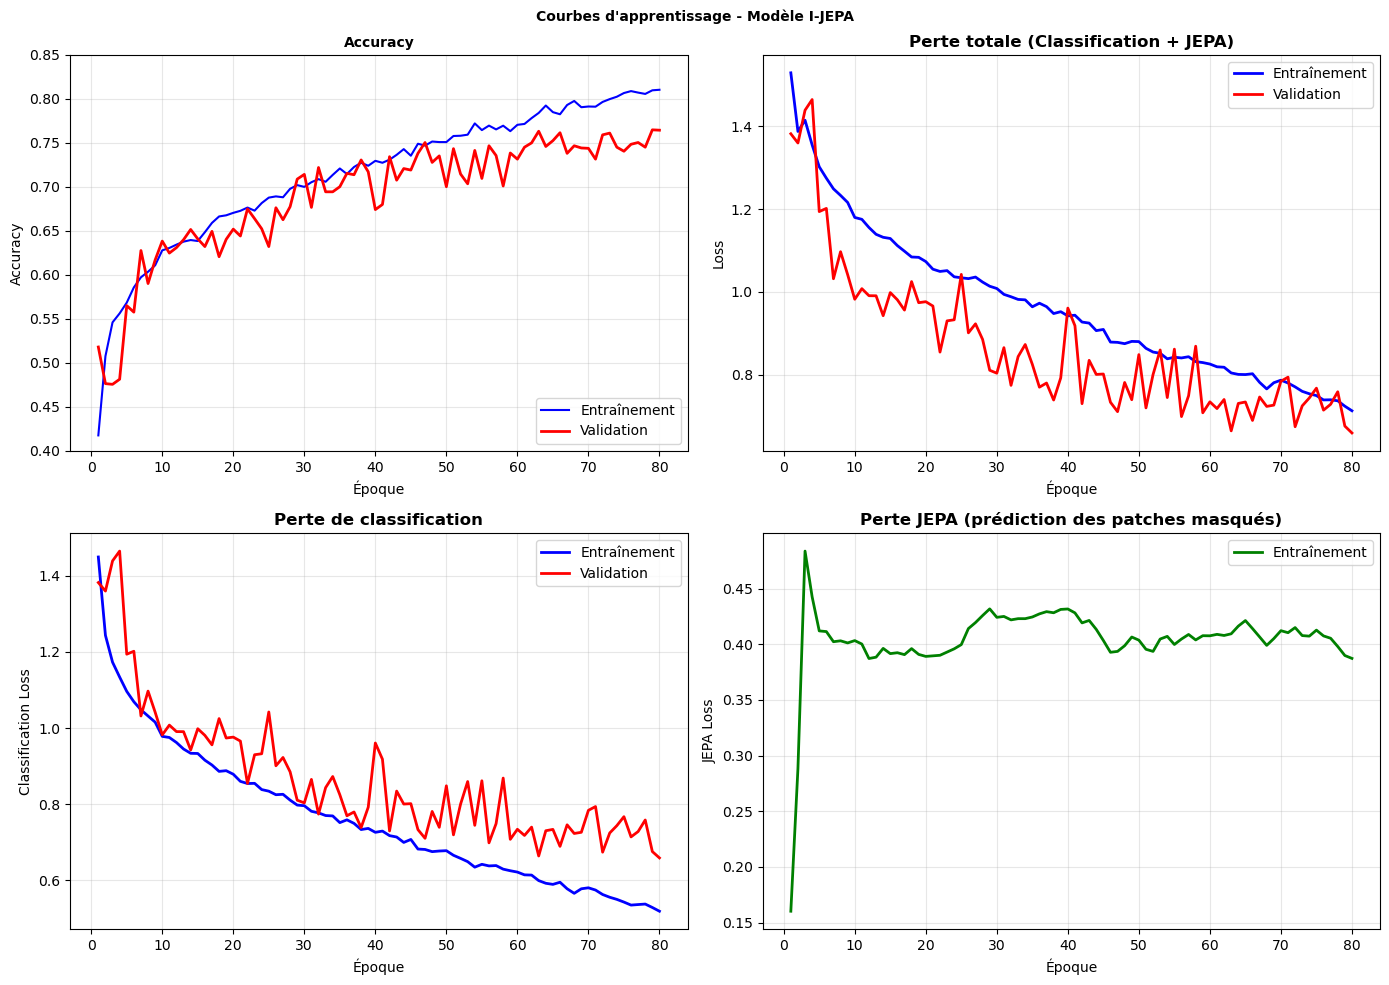

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# RECONSTRUCTION DES DONNÉES À PARTIR DES LOGS
# ============================================

# Données extraites des logs (époques 1 à 80)
epochs = list(range(1, 81))

# Accuracy
train_acc = [
    0.4177, 0.5077, 0.5461, 0.5563, 0.5685, 0.5858, 0.5973, 0.6036, 0.6109, 0.6279,
    0.6306, 0.6344, 0.6378, 0.6396, 0.6385, 0.6485, 0.6591, 0.6664, 0.6677, 0.6705,
    0.6728, 0.6765, 0.6730, 0.6816, 0.6878, 0.6892, 0.6882, 0.6978, 0.7020, 0.7000,
    0.7053, 0.7088, 0.7058, 0.7136, 0.7209, 0.7146, 0.7226, 0.7274, 0.7240, 0.7296,
    0.7274, 0.7309, 0.7364, 0.7429, 0.7354, 0.7490, 0.7469, 0.7515, 0.7509, 0.7509,
    0.7578, 0.7581, 0.7593, 0.7721, 0.7645, 0.7696, 0.7653, 0.7695, 0.7633, 0.7705,
    0.7715, 0.7781, 0.7840, 0.7924, 0.7849, 0.7825, 0.7930, 0.7976, 0.7905, 0.7913,
    0.7911, 0.7965, 0.7997, 0.8024, 0.8066, 0.8088, 0.8071, 0.8056, 0.8097, 0.8103
]

val_acc = [
    0.5181, 0.4765, 0.4757, 0.4815, 0.5651, 0.5577, 0.6277, 0.5902, 0.6170, 0.6384,
    0.6248, 0.6310, 0.6400, 0.6516, 0.6409, 0.6322, 0.6495, 0.6207, 0.6404, 0.6520,
    0.6442, 0.6750, 0.6639, 0.6524, 0.6322, 0.6763, 0.6627, 0.6775, 0.7088, 0.7142,
    0.6767, 0.7220, 0.6944, 0.6944, 0.7002, 0.7154, 0.7138, 0.7306, 0.7171, 0.6742,
    0.6800, 0.7343, 0.7076, 0.7208, 0.7191, 0.7381, 0.7504, 0.7278, 0.7352, 0.7002,
    0.7434, 0.7146, 0.7035, 0.7414, 0.7096, 0.7467, 0.7356, 0.7010, 0.7385, 0.7315,
    0.7451, 0.7500, 0.7632, 0.7459, 0.7525, 0.7615, 0.7381, 0.7467, 0.7442, 0.7438,
    0.7315, 0.7591, 0.7611, 0.7451, 0.7405, 0.7484, 0.7504, 0.7451, 0.7648, 0.7644
]

# Classification Loss
cls_loss = [
    1.4494, 1.2436, 1.1731, 1.1340, 1.0964, 1.0692, 1.0480, 1.0317, 1.0156, 0.9783,
    0.9753, 0.9621, 0.9450, 0.9338, 0.9333, 0.9157, 0.9030, 0.8863, 0.8881, 0.8788,
    0.8601, 0.8544, 0.8549, 0.8385, 0.8343, 0.8250, 0.8261, 0.8108, 0.7978, 0.7961,
    0.7815, 0.7773, 0.7703, 0.7693, 0.7517, 0.7590, 0.7497, 0.7335, 0.7365, 0.7262,
    0.7295, 0.7175, 0.7139, 0.6997, 0.7075, 0.6823, 0.6812, 0.6755, 0.6771, 0.6780,
    0.6659, 0.6578, 0.6492, 0.6347, 0.6422, 0.6380, 0.6389, 0.6295, 0.6253, 0.6218,
    0.6145, 0.6139, 0.5994, 0.5924, 0.5895, 0.5951, 0.5780, 0.5660, 0.5779, 0.5805,
    0.5746, 0.5629, 0.5557, 0.5501, 0.5430, 0.5351, 0.5365, 0.5378, 0.5288, 0.5190
]

val_cls_loss = [
    1.3822, 1.3599, 1.4391, 1.4649, 1.1941, 1.2018, 1.0318, 1.0971, 1.0417, 0.9822,
    1.0078, 0.9908, 0.9906, 0.9425, 0.9983, 0.9809, 0.9560, 1.0249, 0.9739, 0.9763,
    0.9658, 0.8545, 0.9300, 0.9326, 1.0423, 0.9010, 0.9228, 0.8851, 0.8106, 0.8035,
    0.8652, 0.7741, 0.8436, 0.8728, 0.8249, 0.7697, 0.7797, 0.7386, 0.7922, 0.9608,
    0.9183, 0.7298, 0.8345, 0.8005, 0.8015, 0.7333, 0.7105, 0.7810, 0.7394, 0.8484,
    0.7196, 0.8003, 0.8596, 0.7446, 0.8616, 0.6986, 0.7490, 0.8687, 0.7078, 0.7342,
    0.7180, 0.7399, 0.6641, 0.7304, 0.7339, 0.6893, 0.7459, 0.7232, 0.7263, 0.7840,
    0.7939, 0.6741, 0.7245, 0.7437, 0.7673, 0.7142, 0.7283, 0.7586, 0.6757, 0.6590
]

# JEPA Loss
jepa_loss = [
    0.1602, 0.2884, 0.4837, 0.4426, 0.4120, 0.4114, 0.4023, 0.4031, 0.4012, 0.4033,
    0.4002, 0.3872, 0.3884, 0.3963, 0.3916, 0.3924, 0.3907, 0.3961, 0.3909, 0.3891,
    0.3896, 0.3901, 0.3930, 0.3959, 0.3997, 0.4141, 0.4195, 0.4258, 0.4318, 0.4242,
    0.4250, 0.4219, 0.4230, 0.4230, 0.4245, 0.4273, 0.4293, 0.4283, 0.4313, 0.4317,
    0.4282, 0.4192, 0.4214, 0.4134, 0.4034, 0.3928, 0.3936, 0.3987, 0.4065, 0.4037,
    0.3955, 0.3936, 0.4047, 0.4071, 0.3998, 0.4047, 0.4088, 0.4039, 0.4077, 0.4076,
    0.4089, 0.4079, 0.4094, 0.4163, 0.4213, 0.4141, 0.4066, 0.3990, 0.4051, 0.4122,
    0.4104, 0.4150, 0.4078, 0.4073, 0.4127, 0.4075, 0.4054, 0.3980, 0.3899, 0.3873
]

# Total Loss (cls_loss + 0.5 * jepa_loss, car lambda_jepa=0.5)
total_loss = [cls_loss[i] + 0.5 * jepa_loss[i] for i in range(len(cls_loss))]
val_total_loss = val_cls_loss  # car val_jepa_loss = 0

# ============================================
# COURBES D'APPRENTISSAGE
# ============================================

def plot_training_curves(epochs, train_acc, val_acc, total_loss, val_total_loss, 
                         cls_loss, val_cls_loss, jepa_loss, save_path=None):
    """
    Génère les courbes d'apprentissage complètes.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Courbes d\'apprentissage - Modèle I-JEPA', fontsize=10, fontweight='bold')
    
    # 1. Accuracy
    axes[0, 0].plot(epochs, train_acc, 'b-', linewidth=1.5, label='Entraînement')
    axes[0, 0].plot(epochs, val_acc, 'r-', linewidth=2, label='Validation')
    axes[0, 0].set_title('Accuracy', fontsize=10, fontweight='bold')
    axes[0, 0].set_xlabel('Époque')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend(loc='lower right')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].set_ylim(0.4, 0.85)
    
  
    
    # 2. Total Loss
    axes[0, 1].plot(epochs, total_loss, 'b-', linewidth=2, label='Entraînement')
    axes[0, 1].plot(epochs, val_total_loss, 'r-', linewidth=2, label='Validation')
    axes[0, 1].set_title('Perte totale (Classification + JEPA)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Époque')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend(loc='upper right')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Classification Loss
    axes[1, 0].plot(epochs, cls_loss, 'b-', linewidth=2, label='Entraînement')
    axes[1, 0].plot(epochs, val_cls_loss, 'r-', linewidth=2, label='Validation')
    axes[1, 0].set_title('Perte de classification', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Époque')
    axes[1, 0].set_ylabel('Classification Loss')
    axes[1, 0].legend(loc='upper right')
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. JEPA Loss
    axes[1, 1].plot(epochs, jepa_loss, 'g-', linewidth=2, label='Entraînement')
    axes[1, 1].set_title('Perte JEPA (prédiction des patches masqués)', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Époque')
    axes[1, 1].set_ylabel('JEPA Loss')
    axes[1, 1].legend(loc='upper right')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure sauvegardée: {save_path}")
    
    plt.show()

plot_training_curves(epochs, train_acc, val_acc, total_loss, val_total_loss, cls_loss, val_cls_loss, jepa_loss,save_path=str(FIGURES_DIR / "training_curves.png"))

In [85]:
#src.plot_result(historique,name_fig="plot_cls_jepa_1",register_plot=False)

In [26]:
model_jepa = load_model(filepath=str(CLS_MODELS_DIR / "model_jepa_cls_3.keras"))

In [29]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import seaborn as sns
from tqdm import tqdm
def evaluation(model, X_test, y_test, batch_size=32, return_conf_mat=True, return_clss=True, labels=[]):
    
    y_probs_list = []
    
    for i in tqdm(range(0, len(X_test), batch_size), desc="Calcul"):
        batch = X_test[i:i+batch_size]
        # Passer None pour target_data (pas de masques en test)
        logits, _ = model((batch, None), training=False)
        batch_probs = tf.nn.softmax(logits, axis=-1)
        y_probs_list.append(batch_probs.numpy())
    
    # Concaténer tous les résultats
    y_probs = np.concatenate(y_probs_list, axis=0)
    y_pred = np.argmax(y_probs, axis=-1)
    
    print("Prédictions terminées.")
    
    # Matrice de confusion
    conf_matrice = confusion_matrix(y_test, y_pred)
    
    if return_conf_mat:
        print("\n" + "="*60)
        print("MATRICE DE CONFUSION")
        print("="*60)
        print(conf_matrice)
        
        # Matrice de confusion normalisée
        fig, ax = plt.subplots(figsize=(8, 6))
        conf_matrice_nor = conf_matrice.astype('float') / conf_matrice.sum(axis=1)[:, np.newaxis]
        
        sns.heatmap(conf_matrice_nor, annot=True, fmt=".2%", linewidths=.5, ax=ax,
                    xticklabels=labels if labels else range(conf_matrice.shape[0]), 
                    yticklabels=labels if labels else range(conf_matrice.shape[0]),
                    cmap='Blues', cbar=False)
        
        ax.set_ylabel("Classe réelle")
        ax.set_xlabel("Classe prédite")
        ax.set_title("Matrice de confusion normalisée")
        plt.tight_layout()
        plt.show()
    
    if return_clss:
        print("\n" + "="*60)
        print("RAPPORT DE CLASSIFICATION DÉTAILLÉ")
        print("="*60)
        
        target_names = labels if labels else [f"Classe {i}" for i in range(conf_matrice.shape[0])]
        report = classification_report(y_test, y_pred, target_names=target_names, digits=4)
        print(report)
        
        # F1 macro et weighted
        f1_macro = f1_score(y_test, y_pred, average='macro')
        f1_weighted = f1_score(y_test, y_pred, average='weighted')
        
        print(f"\nF1-score macro (non pondéré): {f1_macro:.4f}")
        print(f"F1-score pondéré: {f1_weighted:.4f}")
    
    #return y_pred


In [27]:
X_test = X_test.astype('float32') / 255.0

In [30]:
X_test.max(), X_test.min(), X_test.shape

(np.float32(1.0), np.float32(0.0), (2428, 64, 64, 3))

In [83]:
_, loss = model_jepa((X_test[0:20], X_test[0:20]), training=False)

In [84]:
print(loss)

None


In [72]:
y_pred

<tf.Tensor: shape=(20,), dtype=int64, numpy=array([0, 4, 2, 0, 0, 3, 0, 4, 2, 0, 1, 4, 3, 3, 3, 2, 1, 4, 4, 0])>

Calcul: 100%|██████████| 76/76 [00:13<00:00,  5.80it/s]


Prédictions terminées.

MATRICE DE CONFUSION
[[261   5  34  14  25]
 [ 37 325  10  37  73]
 [ 41   9 324  24  96]
 [  8  13  25 484  25]
 [ 31   5  54   5 463]]


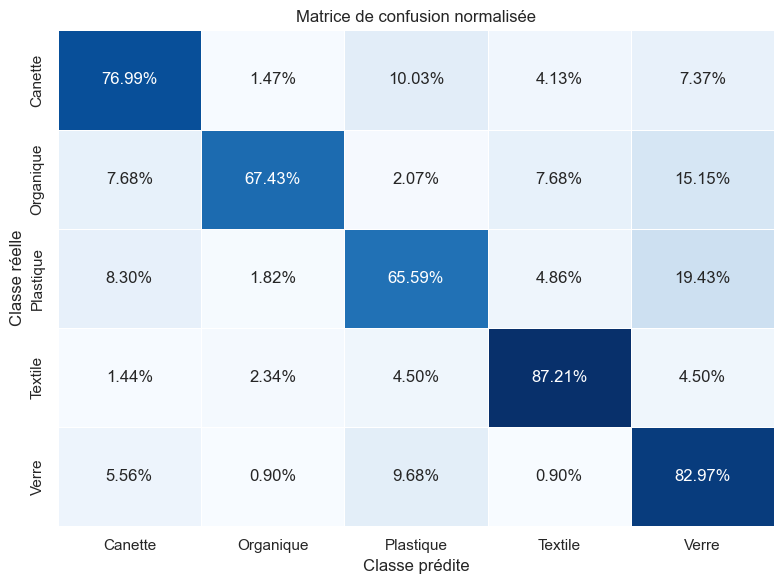


RAPPORT DE CLASSIFICATION DÉTAILLÉ
              precision    recall  f1-score   support

     Canette     0.6905    0.7699    0.7280       339
   Organique     0.9104    0.6743    0.7747       482
   Plastique     0.7248    0.6559    0.6886       494
     Textile     0.8582    0.8721    0.8651       555
       Verre     0.6789    0.8297    0.7468       558

    accuracy                         0.7648      2428
   macro avg     0.7725    0.7604    0.7606      2428
weighted avg     0.7768    0.7648    0.7649      2428


F1-score macro (non pondéré): 0.7606
F1-score pondéré: 0.7649


In [32]:
evaluation(model=model_jepa, X_test=X_test, y_test=y_test, return_conf_mat=True, return_clss=True, labels=df_l.name_label_)

In [91]:
from tqdm import tqdm
def extract_patch_features(model, X):
    features = []

    for img in tqdm(X, desc="Extraction des features"):
        if len(img.shape) == 3:
            img = np.expand_dims(img, 0)

        z = model.encoder(img, training=False)[0].numpy()  # (num_patches, dim)
        features.append(z)

    return features  # ⚠️ liste de tableaux

In [92]:
from sklearn.decomposition import PCA
X_features = extract_patch_features(model_jepa, X_test)


Extraction des features: 100%|██████████| 2428/2428 [01:01<00:00, 39.60it/s]


In [95]:
def build_memory_bank(model, X_train_normal):
    features = extract_patch_features(model, X_train_normal)

    # concat tous les patches
    memory_bank = np.concatenate(features, axis=0)  # (N_patches_total, dim)

    return memory_bank

In [96]:
def compute_anomaly_score(model, img, memory_bank):
    if len(img.shape) == 3:
        img = np.expand_dims(img, 0)

    z = model.encoder(img, training=False)[0].numpy()  # (num_patches, dim)

    distances = []

    for patch in z:
        # distance au patch normal le plus proche
        dist = np.min(np.linalg.norm(memory_bank - patch, axis=1))
        distances.append(dist)

    # score final (important)
    return np.max(distances)

In [97]:
def compute_scores(model, X, memory_bank):
    scores = []

    for img in X:
        score = compute_anomaly_score(model, img, memory_bank)
        scores.append(score)

    return np.array(scores)

In [98]:
memory_bank = build_memory_bank(model=model_jepa, X_train_normal= X_test)
scores_train = compute_scores(model_jepa, X_test, memory_bank)

threshold = np.percentile(scores_train, 95)

print("Threshold:", threshold)

Extraction des features: 100%|██████████| 2428/2428 [01:06<00:00, 36.38it/s]


KeyboardInterrupt: 

In [93]:
pca = PCA(n_components=70)  # ou 100
X_reduced = pca.fit_transform(X_features)

ValueError: Found array with dim 3, while dim <= 2 is required by PCA.

In [72]:
X_reduced.shape


(2428, 70)

In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_reduced)

In [74]:
from sklearn.ensemble import IsolationForest

model_anomaly = IsolationForest(contamination=0.1)
model_anomaly.fit(X_train_scaled)

,n_estimators,100
,max_samples,'auto'
,contamination,0.1
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,None
,verbose,0
,warm_start,False


In [75]:
from sklearn.svm import OneClassSVM

model_anomaly_1 = OneClassSVM(kernel='rbf', nu=0.1)
model_anomaly_1.fit(X_train_scaled)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,nu,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [33]:
df_l = src.Load_data.load_object(DATASET_VALIDATION)

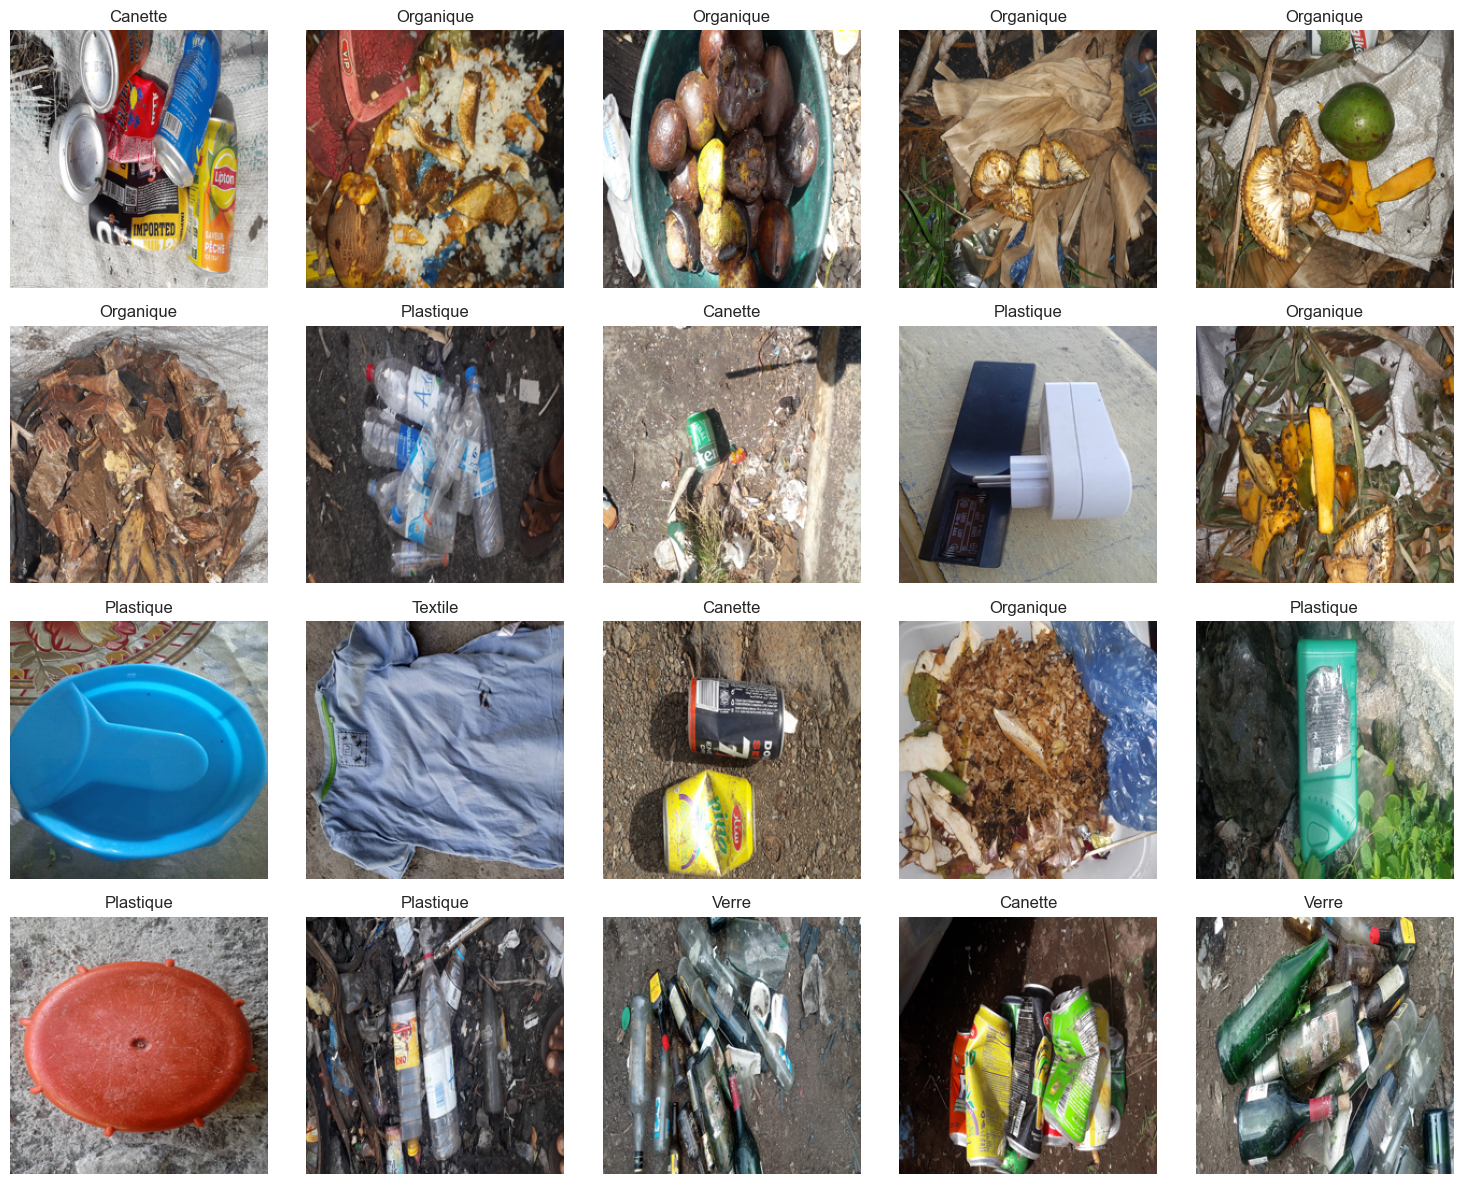

In [59]:
df_l.plot()

In [34]:
df_l.reshape(target_shape=(64,64,3),batch_size=32)

Reshape en batch:   0%|          | 0/17 [00:00<?, ?it/s]

Reshape en batch: 100%|██████████| 17/17 [00:00<00:00, 23.41it/s]


In [35]:
df_l.encodage()

Encodage effectué. Mapping: {'Canette': 0, 'Organique': 1, 'Plastique': 2, 'Textile': 3, 'Verre': 4}


In [36]:
(X_train_l, y_train_l), (X_test_l, y_test_l) = df_l.create_data(test_size=0.00000001)

In [37]:
X_train_l = X_train_l.astype('float32') / 255.0

Calcul: 100%|██████████| 17/17 [00:02<00:00,  6.15it/s]


Prédictions terminées.

MATRICE DE CONFUSION
[[109   3   8   8   1]
 [ 17  59  22  10   0]
 [  3   3 131  27   5]
 [  8   4  21  13   4]
 [ 17   8  27  12  18]]


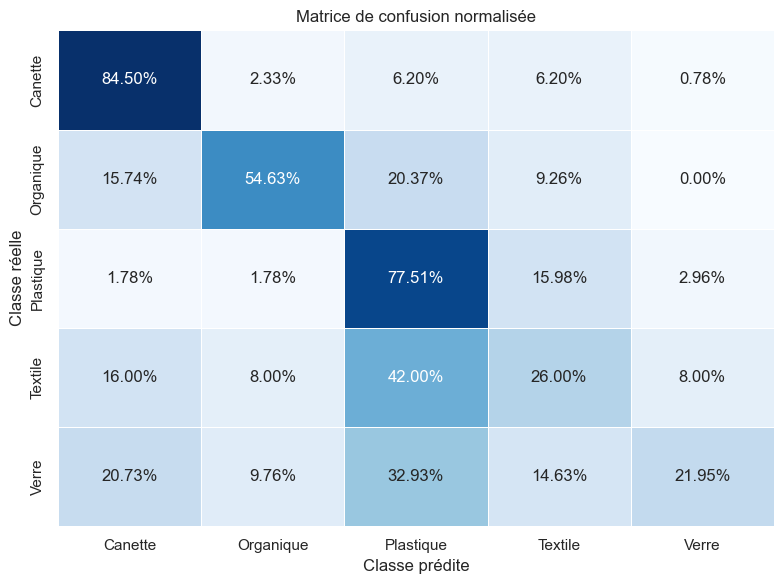


RAPPORT DE CLASSIFICATION DÉTAILLÉ
              precision    recall  f1-score   support

     Canette     0.7078    0.8450    0.7703       129
   Organique     0.7662    0.5463    0.6378       108
   Plastique     0.6268    0.7751    0.6931       169
     Textile     0.1857    0.2600    0.2167        50
       Verre     0.6429    0.2195    0.3273        82

    accuracy                         0.6134       538
   macro avg     0.5859    0.5292    0.5290       538
weighted avg     0.6357    0.6134    0.6005       538


F1-score macro (non pondéré): 0.5290
F1-score pondéré: 0.6005


In [38]:
evaluation(model=model_jepa, X_test=X_train_l, y_test=y_train_l, return_conf_mat=True, return_clss=True, labels=df_l.name_label_)

In [63]:
X_train_l = X_train_l.astype('float32') / 255.0

In [39]:
df_an = src.Load_data.load_object(DATASET_ANOMALIES)

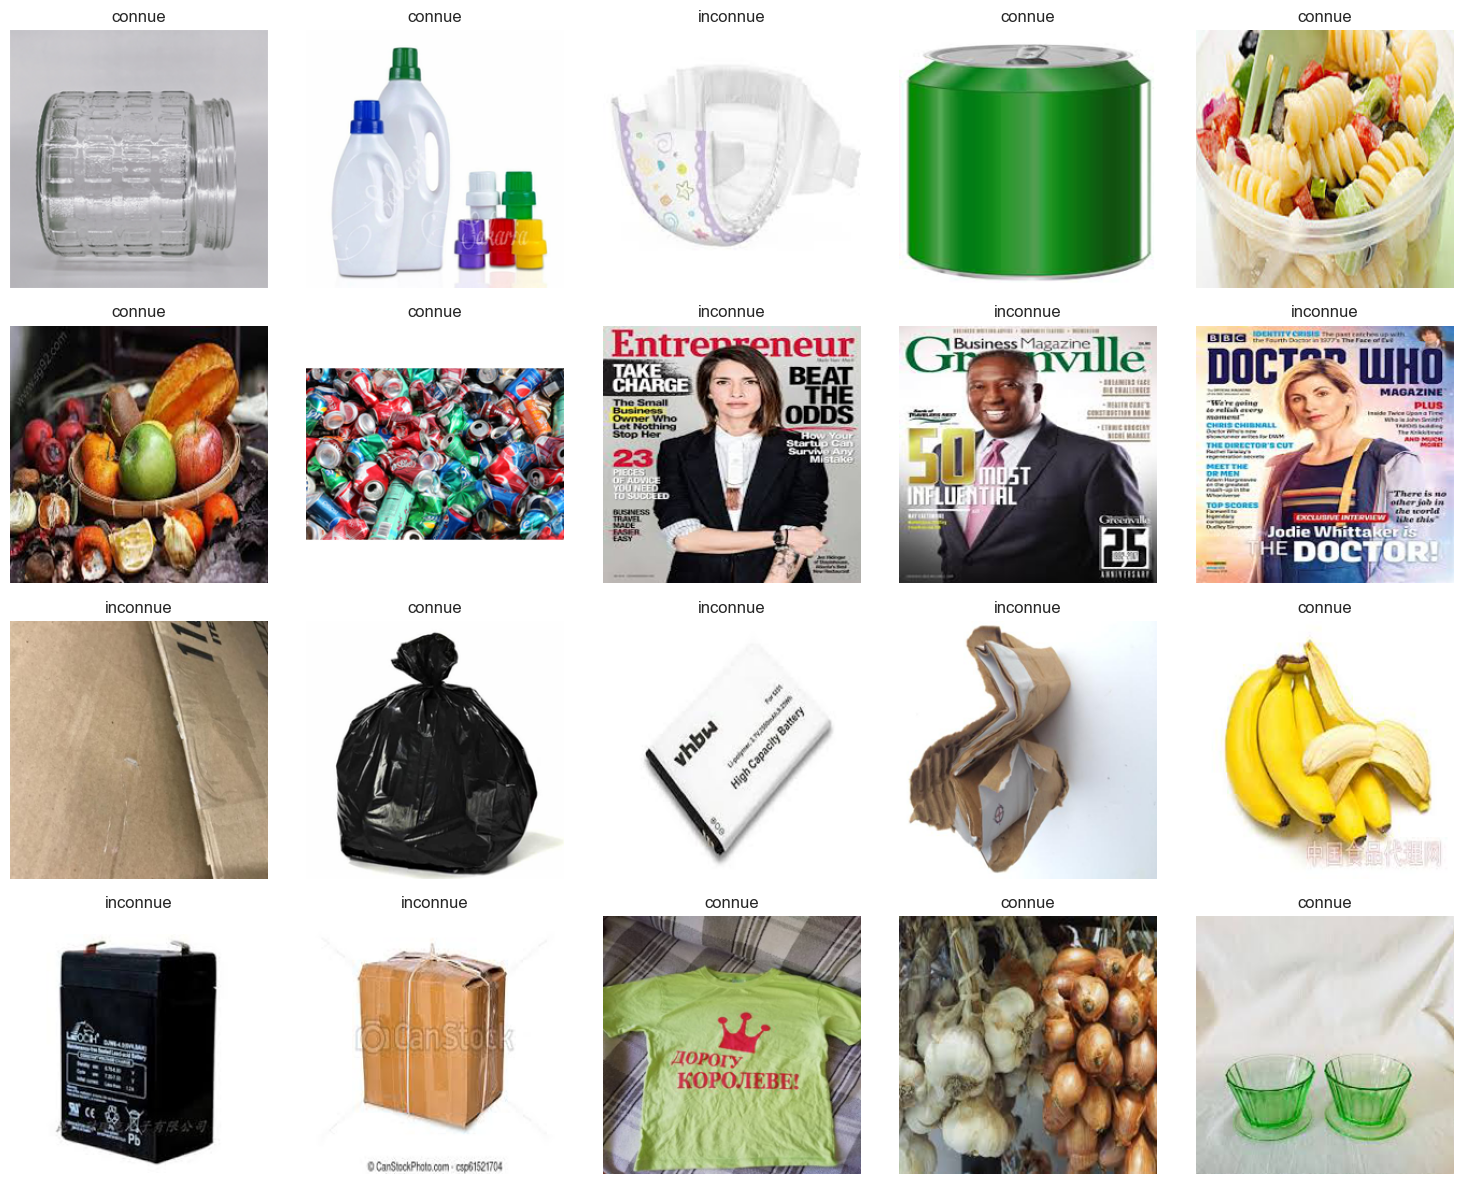

In [40]:
df_an.plot(view_code=True)

In [41]:
df_an.encodage()

Encodage effectué. Mapping: {'connue': 0, 'inconnue': 1}


In [42]:
df_an.reshape(target_shape=(64, 64, 3))

Reshape en batch: 100%|██████████| 125/125 [00:03<00:00, 39.36it/s]


In [43]:
(X_train_an, y_train_an), (_ , _) = df_an.create_data(test_size=0.00000000000001)

In [45]:
X_train_an = X_train_an.astype('float32') / 255.0

In [46]:
X_train_an.max(), X_train_an.min(), X_train_an.shape

(np.float32(1.0), np.float32(0.0), (3999, 64, 64, 3))

In [ ]:
X_test_feat = extract_features_flat(model_jepa, X_train_an)
 # plus grand = plus anormal

Extraction des features: 100%|██████████| 3999/3999 [01:54<00:00, 34.93it/s]


ValueError: X has 8192 features, but StandardScaler is expecting 50 features as input.

In [76]:
X_reduced_an = pca.transform(X_test_feat)
X_test_scaled = scaler.transform(X_reduced_an)

scores = -model_anomaly.score_samples(X_test_scaled) 

In [85]:
threshold = np.percentile(scores, 90)  # ou 95

y_pred = (scores > threshold).astype(int)

In [86]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_train_an, y_pred))

[[1710  289]
 [1889  111]]


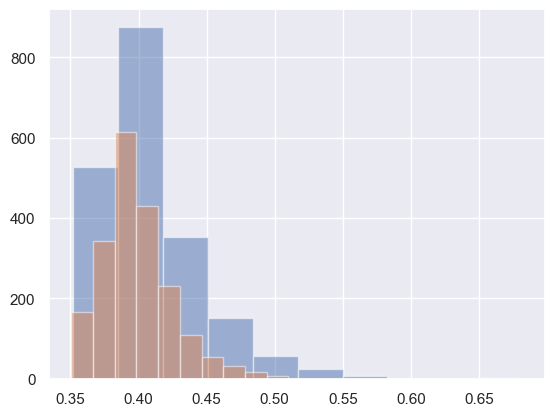

In [87]:
plt.hist(scores[y_train_an==0], alpha=0.5)
plt.hist(scores[y_train_an==1], alpha=0.5)
plt.show()

In [89]:
print("Min score:", scores.min())
print("Max score:", scores.max())
print("Mean normal:", scores[y_train_an==0].mean())
print("Mean anomaly:", scores[y_train_an==1].mean())

Min score: 0.3505880702086117
Max score: 0.6816611507811144
Mean normal: 0.40905744192897664
Mean anomaly: 0.39881269790837265


In [128]:
np.unique(y_pred_best,return_counts=True)

(array([0, 1]), array([   1, 3998]))

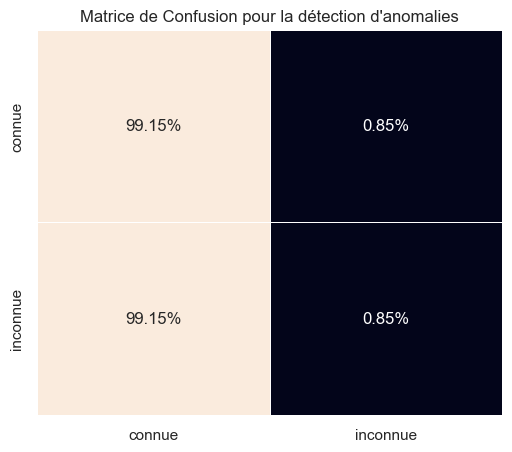

In [59]:
# Matrice de confusio
labels = ['connue', 'inconnue']
f, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_train_an, y_pred)
cm_1 = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_1, annot=True, fmt=".2%", linewidths=.5, ax=ax,
                    xticklabels=labels, yticklabels=labels, cbar=False)
plt.title("Matrice de Confusion pour la détection d'anomalies")
plt.show()